In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [3]:
prefix = '/mnt/staging/'

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

step_0_root = str(STEPS / "step_0") + "/"

mouse = 'cm229'
# data_root =  str(FIGURES / "figureS5") + "/"


In [4]:

with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_26687/3107954218.py:7: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


In [5]:
def new_adjust_box_widths(axes, fac=0.9):
    """
    Adjust the widths of a seaborn-generated boxplot or boxenplot.
    
    Notes
    -----
    - thanks https://github.com/mwaskom/seaborn/issues/1076
    """
    from matplotlib.patches import PathPatch
    from matplotlib.collections import PatchCollection
    
    if isinstance(axes, list) is False:
        axes = [axes]

        
    x_offsets = [-0.8, 0.8]  # Adjust these values to control the separation between hue categories


    display_coordinates_1=[]
    display_coordinates_2=[]
        
        
    # iterating through Axes instances
    for ax in axes:

        # iterating through axes artists:
        for c in ax.get_children():
            # searching for PathPatches
            if isinstance(c, PathPatch) or isinstance(c, PatchCollection):
                if isinstance(c, PathPatch):
                    p = c.get_path()
                    x0_here = c.get_extents().x0
                else:
                    p = c.get_paths()[-1]
                    print('hii')
                    

        
                # getting current width of box:
#                 p = c.get_path()
                verts = p.vertices
                verts_sub = verts[:-1]
                xmin = np.min(verts_sub[:, 0])
                xmax = np.max(verts_sub[:, 0])
                xmid = 0.5 * (xmin + xmax)
                xhalf = 0.5 * (xmax - xmin)

                # setting new width of box
                xmin_new = xmid - fac * xhalf
                xmax_new = xmid + fac * xhalf
                verts_sub[verts_sub[:, 0] == xmin, 0] = xmin_new
                verts_sub[verts_sub[:, 0] == xmax, 0] = xmax_new

                # setting new width of median line
                for l in ax.lines:
                    try:
                        if np.all(l.get_xdata() == [xmin, xmax]):
                            l.set_xdata([xmin_new, xmax_new])
                    except:
                        # /tmp/ipykernel_138835/916607433.py:32: DeprecationWarning: elementwise comparison failed;
                            # this will raise an error in the future.
                                # if np.all(l.get_xdata() == [xmin, xmax]):
                        pass
    pass

In [6]:
load_root = str(FIGURES / "figureS5") + "/"
dict_figure_S5_save_integrated = load_pickle(load_root+'csn_thy1_integrated_compare_save')
for key in dict_figure_S5_save_integrated.keys():
    exec("{} = dict_figure_S5_save_integrated[key]".format(key))

In [7]:
# cm229 ONLY
new_choice_ind={'cm229':{},'cm219':{}}
new_choice_ind['cm229']['M2']=338 # CM229
new_choice_ind['cm229']['S1']=412 # CM229
new_choice_ind['cm229']['M1']=322 # CM229

dict_all = {'cm229':{}}
for mouse in ['cm229']:
    for behavior_type in ['REST','RUN']:
        dict_all[mouse][behavior_type] = {}
        dict_everything_save = load_pickle(load_root+'csn-thy1-compare-trimmed-{}-'.format(behavior_type) + mouse)
        for key in dict_everything_save.keys():
            dict_all[mouse][behavior_type][key] = dict_everything_save[key]

In [8]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
seed_ROI_xy = dict_seed_ROI_xy_mice['cm229']

choice_body_part_dict = {0:'RFP_S1',1:'RFP_M1',2:'RFP_M2'}
choice_dict = {0:new_choice_ind['cm229']['S1'],
               1:new_choice_ind['cm229']['M1'],
               2:[]} #cm229
jrgeco2plot ={};gcamp2plot ={};
for i_bdp in range(3):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if bdp == 'RFP_M2':
        for behavior_type in ['rise_to_lick']:
            y_top_left = seed_ROI_xy['RFP']['y_top_left']
            y_botton_right = seed_ROI_xy['RFP']['y_botton_right']
            x_top_left =seed_ROI_xy['RFP']['x_top_left']
            x_botton_right=seed_ROI_xy['RFP']['x_botton_right']
            exec("jrgeco2plot[bdp+'_'+behavior_type] = np.nanmean(np.nanmean(jrgeco_{}[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)".format(behavior_type))
            exec("gcamp2plot[bdp+'_'+behavior_type]= np.nanmean(np.nanmean(gcamp_{}[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)".format(behavior_type))
    else:
        for behavior_type in ['rise_to_lick']:
            exec("H_jrgeco_here = getH(jrgeco_{},IDX_sorted)".format(behavior_type))
            exec("H_gcamp_here = getH(gcamp_{},IDX_sorted)".format(behavior_type))
            jrgeco2plot[bdp+'_'+behavior_type]=H_jrgeco_here[ind,:]
            gcamp2plot[bdp+'_'+behavior_type]=H_gcamp_here[ind,:]
        
    # add running
    jrgeco2plot[bdp+'_run'] = np.mean(dict_all['cm229']['RUN']['jrgeco2plot'][bdp],axis=0)
    gcamp2plot[bdp+'_run'] = np.mean(dict_all['cm229']['RUN']['gcamp2plot'][bdp],axis=0)
    
    

/Volumes/WX/code/code_ncomms_revision/make_0_prepare/common-functions/f2_utils.py:17: RuntimeWarning: Mean of empty slice
  H[i_H,:]=np.nanmean(data_reshape[temp==True,:],axis=0)


In [9]:
bsl_range = range(len_move_2_rise-6,len_move_2_rise)
MM_jrgeco_norm = MM_jrgeco - np.mean(MM_jrgeco[:,:,bsl_range,:],-2)[:,:,np.newaxis,:]
MM_gcamp_norm = MM_gcamp - np.mean(MM_gcamp[:,:,bsl_range,:],-2)[:,:,np.newaxis,:]
H_jrgeco_norm = getH_4D(MM_jrgeco_norm, IDX_sorted)
H_gcamp_norm = getH_4D(MM_gcamp_norm, IDX_sorted)

/Volumes/WX/code/code_ncomms_revision/make_0_prepare/common-functions/f2_utils.py:28: RuntimeWarning: Mean of empty slice
  H[i_H,:,:]=np.nanmean(data_reshape[temp==True,:,:],axis=0)


In [10]:
stats_pot=pd.DataFrame() 
for i_behavior_type, behavior_type in enumerate(['run','rise_to_lick']):
    for i_fluorophore, fluorophore in enumerate(['jrgeco','gcamp']):
        for i_bdp, bdp in enumerate(['S1', 'M1', 'M2']):
            stats_pot_temp = pd.DataFrame()
            exec("stats_pot_temp['value'] = {}2plot['RFP_'+bdp+'_'+behavior_type]".format(fluorophore))
            stats_pot_temp['behavior_type'] = behavior_type
            stats_pot_temp['fluorophore'] = fluorophore
            stats_pot_temp['bdp'] = bdp
            stats_pot_temp['mouse'] = 'cm229'

            stats_pot = pd.concat([stats_pot, stats_pot_temp])

In [11]:
new_palette = sns.color_palette("Set2")[:2][::-1]
fire_cmap = load_pickle(figure_config_root+'fire_cmap')
palatte_dict = load_pickle(figure_config_root+'palatte_dict')

--- Statistical Results ---
[S1 - run] Thy1 Mean FC: 1.000 | CSNs Mean FC: 1.000 | W = 381.0, p = 9.0665e-01 (n=39)
[S1 - rise_to_lick] Thy1 Mean FC: 1.071 | CSNs Mean FC: 0.897 | W = 30.0, p = 5.0659e-02 (n=16)
[M1 - run] Thy1 Mean FC: 1.000 | CSNs Mean FC: 1.000 | W = 363.0, p = 7.1455e-01 (n=39)
[M1 - rise_to_lick] Thy1 Mean FC: 0.923 | CSNs Mean FC: 1.062 | W = 43.0, p = 2.1143e-01 (n=16)
[M2 - run] Thy1 Mean FC: 1.000 | CSNs Mean FC: 1.000 | W = 354.0, p = 6.2401e-01 (n=39)
[M2 - rise_to_lick] Thy1 Mean FC: 3.276 | CSNs Mean FC: 1.121 | W = 1.0, p = 6.1035e-05 (n=16)


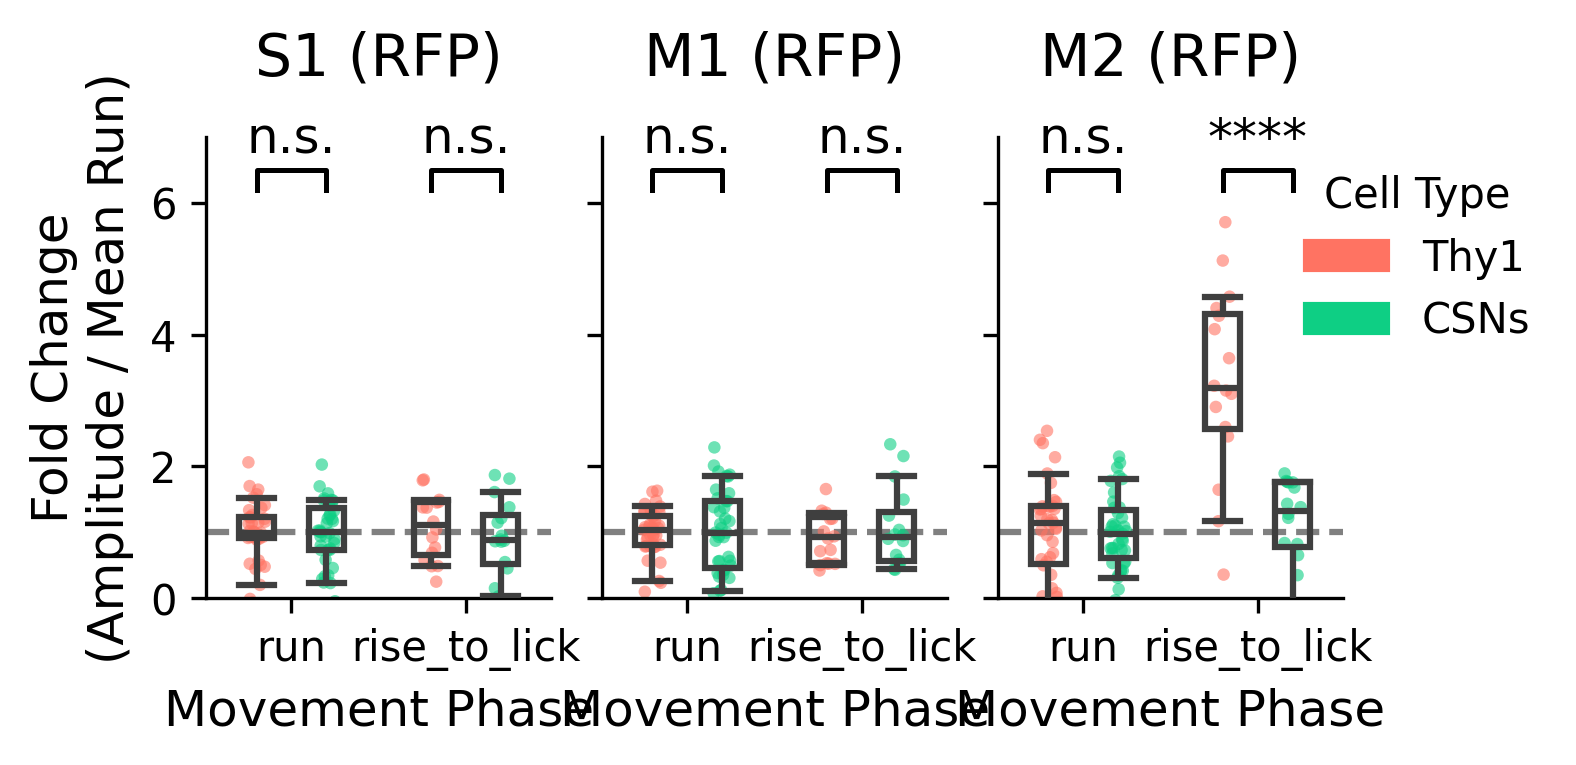

---------------------------


In [ ]:
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches # <--- Added this for the custom legend
from scipy import stats
from matplotlib.gridspec import GridSpec
from matplotlib.patches import PathPatch
from matplotlib.collections import PatchCollection



# === 1. Setup & Data Calculation ===

def new_adjust_box_widths(axes, fac=0.9):
    if not isinstance(axes, (list, np.ndarray)): axes = [axes]
    for ax in axes:
        for c in ax.get_children():
            if isinstance(c, (PathPatch, PatchCollection)):
                p = c.get_path() if isinstance(c, PathPatch) else c.get_paths()[-1]
                verts = p.vertices
                verts_sub = verts[:-1]
                xmin = np.min(verts_sub[:, 0])
                xmax = np.max(verts_sub[:, 0])
                xmid = 0.5 * (xmin + xmax)
                xhalf = 0.5 * (xmax - xmin)
                xmin_new = xmid - fac * xhalf
                xmax_new = xmid + fac * xhalf
                verts_sub[verts_sub[:, 0] == xmin, 0] = xmin_new
                verts_sub[verts_sub[:, 0] == xmax, 0] = xmax_new
                for l in ax.lines:
                    try:
                        if np.all(l.get_xdata() == [xmin, xmax]):
                            l.set_xdata([xmin_new, xmax_new])
                    except:
                        pass

# Data Preparation
stats_pot_list = []
for behavior_type in ['run', 'rise_to_lick']:
    for fluorophore, plot_dict in zip(['jrgeco', 'gcamp'], [jrgeco2plot, gcamp2plot]):
        for bdp in ['S1', 'M1', 'M2']:
            temp = pd.DataFrame()
            temp['value'] = plot_dict[f'RFP_{bdp}_{behavior_type}']
            temp['behavior_type'] = behavior_type
            temp['fluorophore'] = 'Thy1' if fluorophore == 'jrgeco' else 'CSNs'
            temp['bdp'] = bdp
            temp['Epoch_ID'] = np.arange(len(temp))
            stats_pot_list.append(temp)

df_stats = pd.concat(stats_pot_list, ignore_index=True)

# Calculate Fold Change relative to 'run'
df_stats['fold_change'] = np.nan
for bdp in ['S1', 'M1', 'M2']:
    for cell_type in ['Thy1', 'CSNs']:
        mask_run = (df_stats['bdp'] == bdp) & (df_stats['fluorophore'] == cell_type) & (df_stats['behavior_type'] == 'run')
        mean_run = df_stats[mask_run]['value'].mean()
        
        mask_all = (df_stats['bdp'] == bdp) & (df_stats['fluorophore'] == cell_type)
        df_stats.loc[mask_all, 'fold_change'] = df_stats.loc[mask_all, 'value'] / mean_run

# === 2. Figure Setup with GridSpec ===

plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(10, 4), dpi=300)
gs = GridSpec(100, 100)

# Define 3 separate axes side-by-side using GridSpec
y_top, y_bot = 10, 60
width_here = 15; width_gap =2
ax0 = fig.add_subplot(gs[y_top:y_bot, 5:5+width_here]);width_start = 5+width_here+width_gap
ax1 = fig.add_subplot(gs[y_top:y_bot, width_start:width_start+width_here], sharey=ax0);width_start = width_start+width_here+width_gap
ax2 = fig.add_subplot(gs[y_top:y_bot, width_start:width_start+width_here], sharey=ax0)

axes = [ax0, ax1, ax2]
regions = ['S1', 'M1', 'M2']
my_pal = {'Thy1': '#ff7362', 'CSNs': '#0ecf84'}

# Y-Axis Limits and Bracket Placement
Y_MAX_DISPLAY = 7.0
y_bracket = 6.5     # Height of the bracket bar
bracket_drop = 0.3   # How far down the bracket legs drop
x_offset = 0.2       # Distance from center tick to the box centers due to dodge

print("--- Statistical Results ---")

for ax, bdp in zip(axes, regions):
    df_region = df_stats[df_stats['bdp'] == bdp]
    
    # Plotting
    sns.boxplot(ax=ax, data=df_region, x='behavior_type', y='fold_change',
                hue='fluorophore', saturation=1, showfliers=False,
                whis=(5, 90), boxprops={'zorder': 5, 'facecolor': 'none'}, 
                linewidth=1.5, zorder=10)
    
    sns.stripplot(ax=ax, data=df_region, x='behavior_type', y='fold_change',
                  hue='fluorophore', dodge=True, palette=my_pal,
                  size=3, alpha=0.6, zorder=2)
    
    # Baseline line
    ax.axhline(1.0, color='gray', linewidth=1.5, linestyle='dashed', zorder=0)
    
    # Subplot Formatting
    ax.set_ylim([0, Y_MAX_DISPLAY])
    ax.set_title(f'{bdp} (RFP)', fontsize=14, pad=15)
    ax.set_xlabel('Movement Phase', fontsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    if ax == axes[0]:
        ax.set_ylabel('Fold Change\n(Amplitude / Mean Run)', fontsize=12)
    else:
        ax.set_ylabel('')
        ax.tick_params(labelleft=False) # Hide y-ticks on middle and right panels
        
    # Legend Management (Custom Patches)
    ax.get_legend().remove() # Remove seaborn's messy default legend from ALL plots
    
    if ax == axes[-1]:
        # Manually build the legend on the last plot 
        thy1_patch = mpatches.Patch(color=my_pal['Thy1'], label='Thy1')
        csn_patch = mpatches.Patch(color=my_pal['CSNs'], label='CSNs')
        ax.legend(handles=[thy1_patch, csn_patch], loc='upper right', bbox_to_anchor=(1.65, 1), 
                  title="Cell Type", frameon=False)
        
    # Statistics & Brackets (For both 'run' and 'lick')
    for x_idx, phase in enumerate(['run', 'rise_to_lick']):
        df_phase = df_region[df_region['behavior_type'] == phase]
        paired_data = df_phase.pivot(index='Epoch_ID', columns='fluorophore', values='fold_change').dropna()

        # --- NEW CODE: Calculate the exact means ---
        mean_thy1 = paired_data['Thy1'].mean()
        mean_csns = paired_data['CSNs'].mean()
        
        stat, p_val = stats.wilcoxon(paired_data['Thy1'], paired_data['CSNs'])

        print(f"[{bdp} - {phase}] Thy1 Mean FC: {mean_thy1:.3f} | CSNs Mean FC: {mean_csns:.3f} | W = {stat:.1f}, p = {p_val:.4e} (n={len(paired_data)})")
        
        if p_val < 0.0001: sig_str = "****"
        elif p_val < 0.001: sig_str = "***"
        elif p_val < 0.01: sig_str = "**"
        elif p_val < 0.05: sig_str = "*"
        else: sig_str = "n.s."
        
        # Draw Bracket
        x1, x2 = x_idx - x_offset, x_idx + x_offset
        ax.plot([x1, x1, x2, x2], [y_bracket - bracket_drop, y_bracket, y_bracket, y_bracket - bracket_drop], 
                lw=1.2, color='k')
        
        # Place Star
        ax.text(x_idx, y_bracket + 0.1, sig_str, ha='center', va='bottom', color='black', fontsize=12)

# Adjust box widths uniformly
new_adjust_box_widths(axes, fac=0.5)

plt.savefig('fig5-S1_M1_M2_FoldChange_Stats.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()
print("---------------------------")

In [13]:
# Isolate the data for M2 during the Lick phase
m2_lick = df_stats[(df_stats['bdp'] == 'M2') & (df_stats['behavior_type'] == 'rise_to_lick')]

# Extract Thy1 and CSN arrays
thy1_vals = m2_lick[m2_lick['fluorophore'] == 'Thy1']['fold_change']
csn_vals = m2_lick[m2_lick['fluorophore'] == 'CSNs']['fold_change']

# Print the exact Mean and Median
print(f"Thy1 (M2 Lick): Mean = {thy1_vals.mean():.2f}x, Median = {thy1_vals.median():.2f}x")
print(f"CSNs (M2 Lick): Mean = {csn_vals.mean():.2f}x, Median = {csn_vals.median():.2f}x")

Thy1 (M2 Lick): Mean = 3.28x, Median = 3.19x
CSNs (M2 Lick): Mean = 1.12x, Median = 1.33x


In [14]:
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'

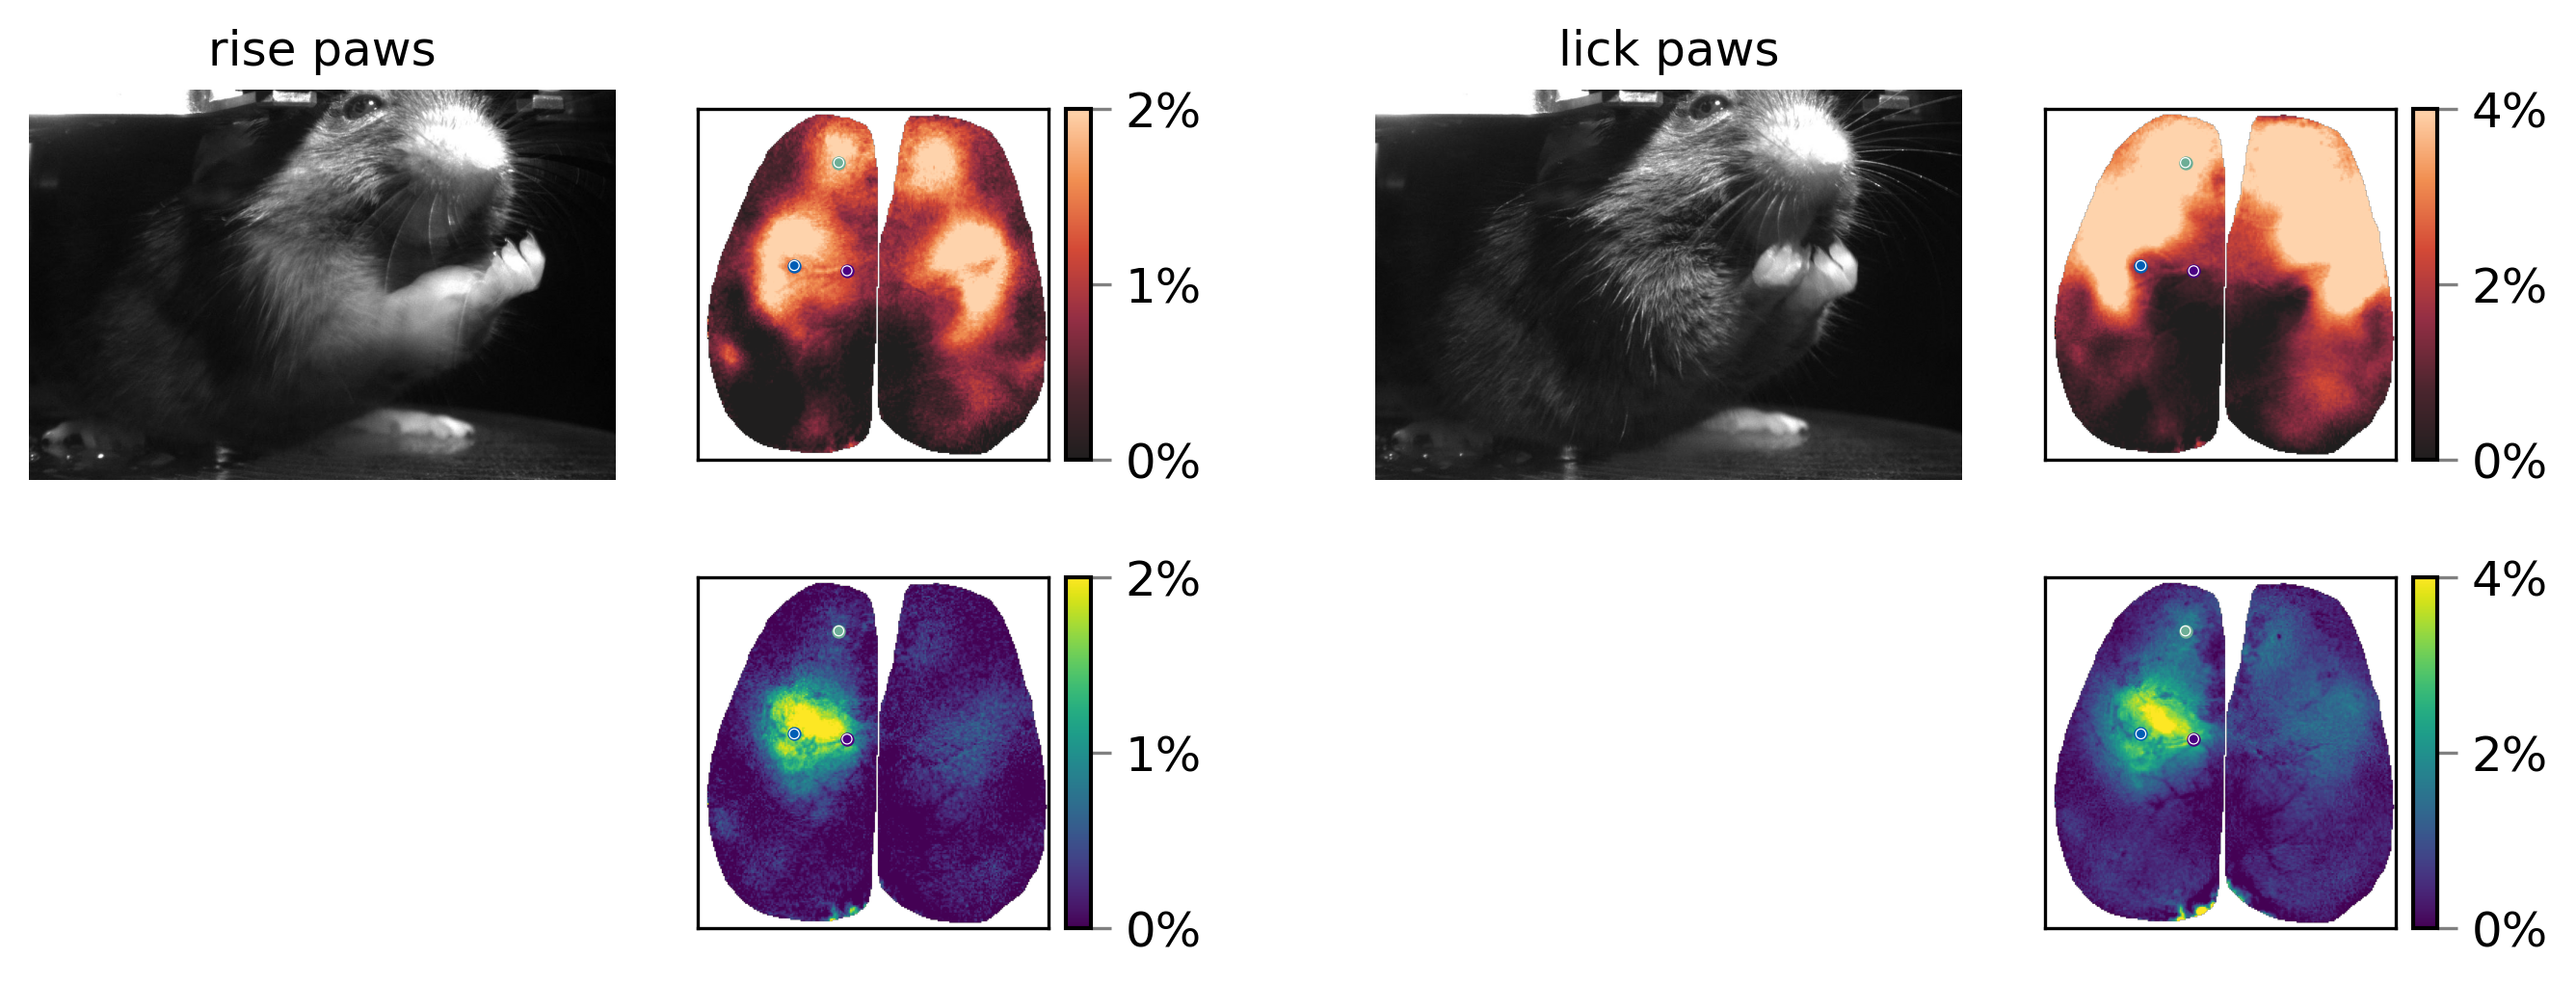

In [ ]:
plt.style.use('default')
gs = GridSpec(100,100)

plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset = 20; x_width = 5; y_width = 5
x_start = x_offset 
x_stop = x_start+ 9
y_start = y_offset 
y_stop = y_start+6

# webcam snapshots
for i_ax in range(0,2):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.axis('off')".format(i_ax))
    x_start = x_stop + 11
    x_stop = x_start + 9

# thy1-jrgeco
x_start = x_offset + 10
x_stop = x_start+6
y_start = y_offset 
y_stop = y_start+6
for i_ax in range(2,4):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([]);ax{}.set_yticks([]);ax{}.set_xticks([]);ax{}.set_yticks([])".format(i_ax,i_ax,i_ax,i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    x_start = x_stop + 9+5
    x_stop = x_start + 6
    
# csn-gcamp 
x_start = x_offset + 10
x_stop = x_start+6
y_start = y_offset +7
y_stop = y_start+6
for i_ax in range(4,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([]);ax{}.set_yticks([]);ax{}.set_xticks([]);ax{}.set_yticks([])".format(i_ax,i_ax,i_ax,i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    x_start = x_stop + 9+5
    x_stop = x_start + 6
    

    

    
##########################################
ax0.imshow(dict_webcam_img['integrated_rise'],cmap='gray');ax0.set_title('rise paws')
ax1.imshow(dict_webcam_img['integrated_lick'],cmap='gray');ax1.set_title('lick paws')
sbp2 = ax2.imshow(brain_map_jrgeco_rise,cmap=fire_cmap,vmin=0,vmax=0.02)
sbp4 = ax4.imshow(brain_map_gcamp_rise,cmap='viridis',vmin=0,vmax=0.02)
sbp3 = ax3.imshow(brain_map_jrgeco_lick,cmap=fire_cmap,vmin=0,vmax=0.04)
sbp5 = ax5.imshow(brain_map_gcamp_lick,cmap='viridis',vmin=0,vmax=0.04)



##########################################
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
for i_sbp in range(2,6):
    exec("div = make_axes_locatable(ax{})".format(i_sbp))
    cax = div.append_axes('right', '7%', '5%')
    exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_sbp))
    cb.ax.tick_params(labelsize=12,length=5,color='gray')
    cb.ax.yaxis.tick_right()
    # cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(1)

for i_ax in range(2,6):
    for i_key,key in enumerate(new_choice_ind['cm229']):
        ind = new_choice_ind['cm229'][key]
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=6,color=palatte_dict['RFP_'+key])".format(i_ax))
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=6,facecolors='none',linewidths=0.3, edgecolors='white')".format(i_ax))



plt.savefig('fig5-compare-integrated-motif-and-running.svg',format='svg',dpi=300)